### Part 1 - Import

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

In [17]:
# Download required data files
!pip install -q gdown

import os
import gdown

files = [
    ("https://drive.google.com/file/d/1zgEuIeabcNs2p82TjQJCXQEWhxjzfFjK/view?usp=sharing", "data/NYCTaxiFares.csv"),
]

for url, dest in files:
    directory = os.path.dirname(dest)
    if directory:
        os.makedirs(directory, exist_ok=True)
    if not os.path.exists(dest):
        gdown.download(url, dest, quiet=False, fuzzy=True)
    else:
        print(f"{dest} already exists - skipping download.")

Downloading...
From: https://drive.google.com/uc?id=1zgEuIeabcNs2p82TjQJCXQEWhxjzfFjK
To: /Users/amir/WORK_DIR/github/ai_course/Sec 03 - Data Visualization/data/NYCTaxiFares.csv
100%|██████████| 8.99M/8.99M [00:05<00:00, 1.71MB/s]


In [3]:
df = pd.read_csv('NYCTaxiFares.csv') # head, describe

### Part 2 - Haversine

The distance formula works out to

${\displaystyle d=2r\arcsin \left({\sqrt {\sin ^{2}\left({\frac {\varphi _{2}-\varphi _{1}}{2}}\right)+\cos(\varphi _{1})\:\cos(\varphi _{2})\:\sin ^{2}\left({\frac {\lambda _{2}-\lambda _{1}}{2}}\right)}}\right)}$

where

$\begin{split} r&: \textrm {radius of the sphere (Earth's radius averages 6371 km)}\\
\varphi_1, \varphi_2&: \textrm {latitudes of point 1 and point 2}\\
\lambda_1, \lambda_2&: \textrm {longitudes of point 1 and point 2}\end{split}$

In [4]:
# this function returns a float which is in kilometers
def haversine_distance(df, lat1, long1, lat2, long2):
    """
    Calculates the haversine distance between 2 sets of GPS coordinates in df
    """
    r = 6371  # average radius of Earth in kilometers

    # convert to radians
    phi1 = np.radians(df[lat1])
    phi2 = np.radians(df[lat2])

    delta_phi = np.radians(df[lat2]-df[lat1])
    delta_lambda = np.radians(df[long2]-df[long1])

    a = np.sin(delta_phi/2)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda/2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))
    d = (r * c) # in kilometers

    return d

In [5]:
df['dist_km'] = haversine_distance(df,
                                   'pickup_latitude',
                                   'pickup_longitude',
                                   'dropoff_latitude',
                                   'dropoff_longitude')

In [6]:
# check the columns and drop the irrelevant ones
df.drop(['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude'],
        axis = 1,
        inplace=True)

In [7]:
df.drop(['fare_class', 'passenger_count'], axis = 1, inplace=True)

### Part 3- Feature engineering pickup_datetime

In [8]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime']) # day, month

In [9]:
df['pickup_datetime'] = df['pickup_datetime'] - pd.Timedelta(hours=4)

In [10]:
df['Hour'] = df['pickup_datetime'].dt.hour

In [11]:
df['DayorNight'] = np.where((df['Hour'] >= 6) & (df['Hour'] <= 18), 'day', 'night')

In [12]:
df['Weekday'] = df['pickup_datetime'].dt.day_name()

In [13]:
df.drop(['pickup_datetime'], axis=1, inplace=True) # columns, dtypes

### Part 4 - Visualization

<Axes: xlabel='Hour', ylabel='Weekday'>

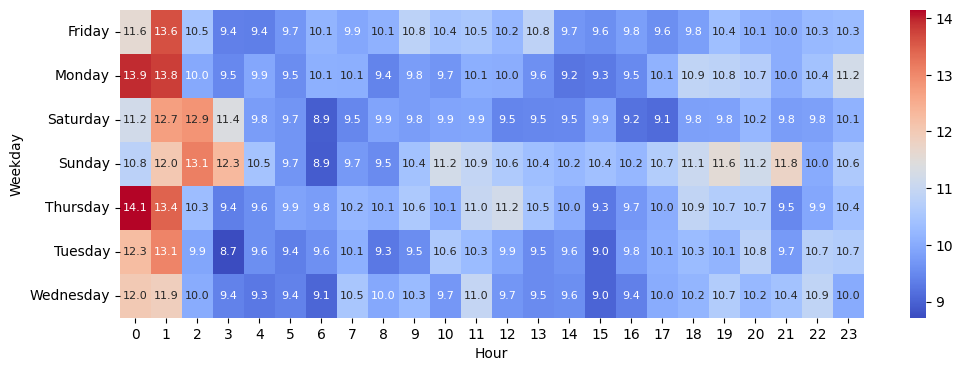

In [14]:
import matplotlib.pyplot as plt

average_fare = df.groupby(['Weekday', 'Hour'])['fare_amount'].mean().reset_index()

pivot_table = average_fare.pivot(index='Weekday',
                                 columns='Hour',
                                 values='fare_amount')

# Create a heatmap
plt.figure(figsize=(12, 4))
sns.heatmap(pivot_table,
            cmap='coolwarm',
            annot=True,
            fmt='.1f',
            annot_kws={'size': 8}) # fmt -> annotation format

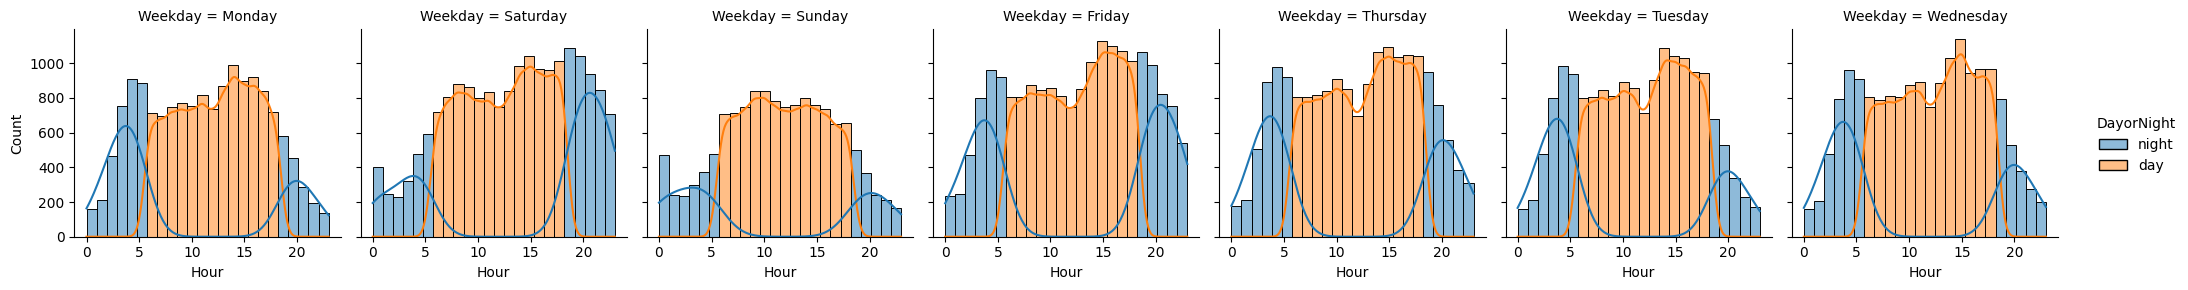

In [15]:
g = sns.displot(data=df,
                x='Hour',
                col='Weekday',
                kind='hist',
                hue='DayorNight',
                bins=df['Hour'].nunique(),
                height=3,
                aspect=1.0,
                common_norm=False,
                kde=True)